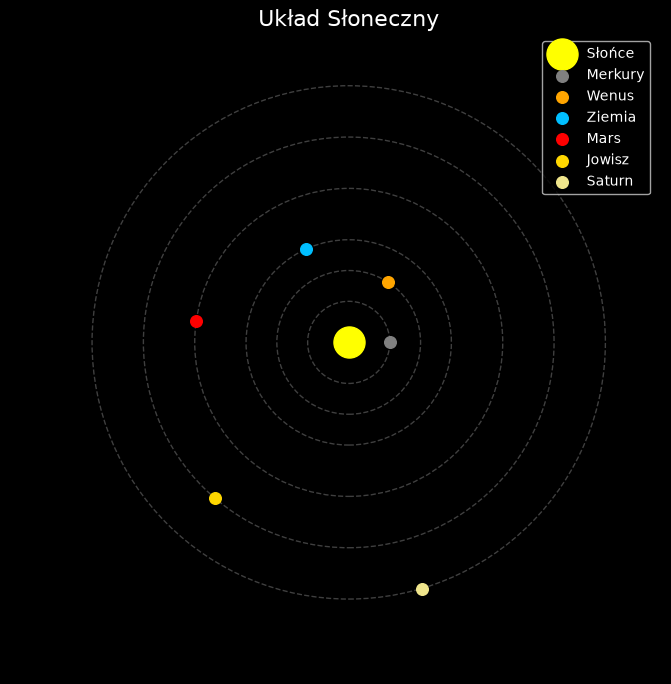

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Dane planet: nazwa, odległość od Słońca, kolor
planety = {
    "Merkury": (0.4, "gray"),
    "Wenus": (0.7, "orange"),
    "Ziemia": (1.0, "deepskyblue"),
    "Mars": (1.5, "red"),
    "Jowisz": (2.0, "gold"),
    "Saturn": (2.5, "khaki")
}

fig, ax = plt.subplots(figsize=(8, 8))
fig.patch.set_facecolor("black")
ax.set_facecolor("black")

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_aspect("equal")

ax.set_title("Układ Słoneczny", color="white", fontsize=16)

# Słońce
ax.scatter(0, 0, s=500, color="yellow", label="Słońce")

# Orbity planet
for nazwa, (r, kolor) in planety.items():
    orbita = plt.Circle((0, 0), r, color="white",
                        fill=False, linestyle="--", alpha=0.25)
    ax.add_patch(orbita)

# Punkty reprezentujące planety
punkty = {}

for nazwa, (r, kolor) in planety.items():
    punkty[nazwa] = ax.scatter([], [], s=70,
                               color=kolor, label=nazwa)

ax.legend(loc="upper right", facecolor="black",
          labelcolor="white")

# Animacja
def aktualizuj(klatka):
    for i, (nazwa, (r, kolor)) in enumerate(planety.items()):
        kat = klatka * 0.03 / (r ** 1.5) + i

        x = r * np.cos(kat)
        y = r * np.sin(kat)

        punkty[nazwa].set_offsets([x, y])

    return list(punkty.values())

animacja = FuncAnimation(
    fig, aktualizuj, frames=500,
    interval=30, blit=True
)

plt.show()
